## Imports

In [1]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
import os
os.environ["PATH"] += os.pathsep + r"C:\Program Files\Graphviz\bin"

import graphviz
print(graphviz.version())
from graphviz import Digraph

(16, 1, 0)


## Visualization Functions

In [3]:
def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._children:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
  
  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot

## Basic Unit

implemented tanh using exp.

In [4]:
class Node:
    def __init__(self, data, children=(), operation='', label=''):
        self.data = data
        self.grad = 0.0 # initialize gradients as 0
        self.label = label
        self._children = set(children)
        self._op = operation
        self._backward = lambda: None 
        
    def __repr__(self):
        return f"Node({self.label}: data={self.data})"
        
    def __add__(self, other):
        other = other if isinstance(other, Node) else Node(other)
        out = Node(self.data + other.data, children=(self, other), operation='+')
        
        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        
        return out
    
    def __mul__(self, other):
        other = other if isinstance(other, Node) else Node(other)
        out = Node(self.data * other.data, children=(self, other), operation='*')
        
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        
        return out
    
    def __pow__(self, other):
        assert isinstance(other, float) or isinstance(other, int)
        out = Node(self.data ** other, children=(self, ), operation='**')
        
        def _backward():
            self.grad += (other * self.data ** (other - 1.0)) * out.grad
            # we use self.data, not self - if we use self, then a lot of calls would be made to self.__pow__
            # since we are assuming the `other` is a constant, we do not compute its grad
        out._backward = _backward
        
        return out
    
    def __rmul__(self, other):
        # other * self when other is int or float
        return self * other
    
    def __radd__(self, other):
        # other + self when other is int or float
        return self + other
    
    def __neg__(self):
        return self * (-1.0)
    
    def __sub__(self, other):
        return self + (-other)
    
    def __rsub__(self, other):
        # other - self when other is int or float
        return other + (-self)
    
    def __truediv__(self, other):
        return self * other ** (-1.0)
    
    def __rtruediv__(self, other):
        # other / self when other is int or float
        return other * self ** (-1.0)
    
    def exp(self):
        out = Node(math.exp(self.data), children=(self, ), operation='exp')
        
        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward
        
        return out
    
    def tanh(self):
        num = (2.0 * self).exp() - 1.0 
        den = (2.0 * self).exp() + 1.0
        out = num / den
        out.label = 'tanh(.)'
        return out
    
    def backward(self):
        top = []
        visited = set()
        
        def top_sort(v):
            if v not in visited:
                visited.add(v)
                for node in v._children:
                    top_sort(node)
                top.append(v)
        top_sort(self)
        
        self.grad = 1.0
        for node in reversed(top):
            node._backward()

## Neural Network Utilities

Neuron, Layer, MLP - with tanh activation for now.

In [5]:
class Neuron:
    def __init__(self, nin):
        self.weight = [Node(random.uniform(-1, 1)) for _ in range(nin)]
        self.bias = Node(random.uniform(-1, 1))
        
    def __call__(self, x):
        out = sum((w1 * x1 for w1, x1 in zip(self.weight, x)), self.bias)
        return out.tanh()
    
    def parameters(self):
        return self.weight + [self.bias]
    
class Layer:
    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]
    
    def __call__(self, x):
        out = [n(x) for n in self.neurons]
        return out[0] if len(out) == 1 else out
    
    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]
    
class MLP:
    def __init__(self, nin, nouts):
        sizes = [nin] + nouts
        self.layers = [Layer(sizes[i], sizes[i+1]) for i in range(len(nouts))]
        
    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x        
    
    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

In [6]:
net = MLP(3, [4, 4, 1])
x = [2.0, 3.0, -1.0]
net(x)
print(f"Number of parameters: {len(net.parameters())}")

Number of parameters: 41


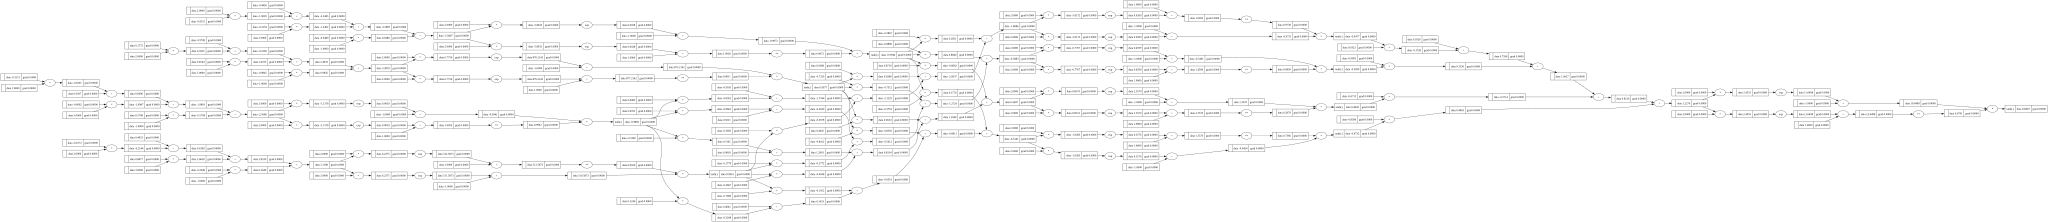

In [7]:
draw_dot(net(x))

## Dummy Dataset

In [8]:
X = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0]
]
y = [1.0, -1.0, -1.0, 1.0]

lr = 0.05

epochs = 100

## Training and Testing Utilities

In [9]:
# defining the inference for the model
def predict(model, X):
    outs = []
    for x in X:
        outs.append(model(x))
    return outs

In [10]:
# defining the loss function
MSE = lambda yout, yact: 0.5 * sum(((y1 - y0) ** 2 for y1, y0 in zip(yout, yact)))

In [11]:
# defining the optimization function
def step(model, lr):
    for p in model.parameters():
        # first call a loss.backward() before calling step()
        # if we do p -= then it will create a new Node object
        p.data -= lr*p.grad

# clear gradients after one step of backprop
def zero_grad(model):
    for p in model.parameters():
        p.grad = 0.0

Epoch 0, Loss 0.3153740781226668, Prediction ['0.842', '-0.586', '-0.390', '0.750']
Epoch 10, Loss 0.053058966557431524, Prediction ['0.908', '-0.868', '-0.759', '0.852']
Epoch 20, Loss 0.028512288751154337, Prediction ['0.930', '-0.908', '-0.823', '0.888']
Epoch 30, Loss 0.019367959085380644, Prediction ['0.942', '-0.926', '-0.855', '0.907']
Epoch 40, Loss 0.0146217065450891, Prediction ['0.949', '-0.937', '-0.874', '0.919']
Epoch 50, Loss 0.011724813893443113, Prediction ['0.954', '-0.944', '-0.887', '0.927']
Epoch 60, Loss 0.00977618538184086, Prediction ['0.957', '-0.949', '-0.897', '0.933']
Epoch 70, Loss 0.008377339322188966, Prediction ['0.960', '-0.953', '-0.905', '0.938']
Epoch 80, Loss 0.007325215726713291, Prediction ['0.963', '-0.956', '-0.911', '0.942']
Epoch 90, Loss 0.006505596954671283, Prediction ['0.965', '-0.959', '-0.916', '0.945']


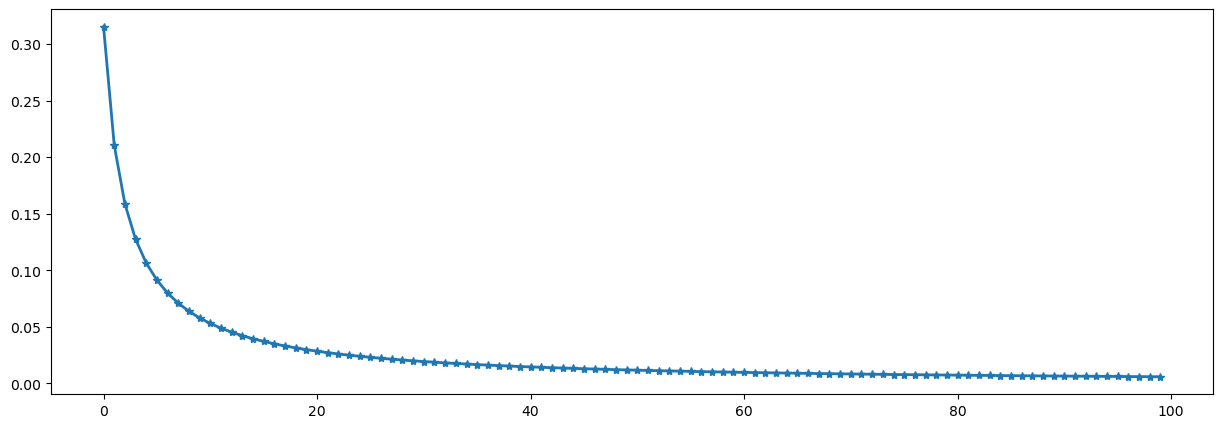

In [12]:
# training loop, showing predictions, plotting losses
losses = []
for ep in range(epochs):
    zero_grad(net)
    pred = predict(net, X)
    loss = MSE(pred, y)
    losses.append(loss.data)
    loss.backward()
    step(net, lr)
    if ep%10 == 0:
        print(f"Epoch {ep}, Loss {loss.data}, Prediction {[f'{pr.data:.3f}' for pr in pred]}")
        
plt.figure(figsize=(15,5))
plt.plot(range(epochs), losses, '*-', linewidth=2)
plt.show()